# RiskShip — Programación Genética reproducible

Predicción de `is_lost` al crear el envío. Mismo conjunto y particiones RNA,
métricas por artículo, evolución de árboles DEAP en CPU.

Este notebook contiene el código necesario y puede abrirse fuera del repositorio.
Modo inicial: **smoke**, 30 individuos, 3 generaciones, fitness con todo train.
`MODE='full'` ejecuta las tres configuraciones, selección con validación, cinco
semillas y cinco ablaciones sin dominio. Puede tardar varios minutos.

Los datos son corporativos. La ejecución local usa el Parquet existente.
Para Colab, cargar datos requiere autorización de su propietario; el notebook
no monta Drive ni carga archivos automáticamente. Cambiar `CLOUD_DATA_AUTHORIZED`
solo si ya se cuenta con esa autorización.

El score del árbol no está calibrado. Test se evalúa después de seleccionar
árbol/configuración/umbral; la comparación usa un test ya conocido del RNA.


In [1]:
import importlib.util, os, subprocess, sys
from pathlib import Path
MODE = 'smoke'  # 'full' para el protocolo completo
CLOUD_DATA_AUTHORIZED = False
IN_COLAB = importlib.util.find_spec('google.colab') is not None if importlib.util.find_spec('google') else False
if IN_COLAB and not CLOUD_DATA_AUTHORIZED:
    raise RuntimeError('Se requiere autorización para usar datos corporativos en Colab. También puede ejecutarse localmente.')
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'deap==1.4.4', 'pandas==2.3.3', 'numpy==2.5.3',
                           'scikit-learn==1.9.1', 'pyarrow==24.0.0', 'matplotlib==3.11.2'])
print('Python:', sys.version.split()[0], '| Modo:', MODE)


Python: 3.12.3 | Modo: smoke


## Datos

`DATA_PATH` puede apuntar a un Parquet local. En Colab autorizado se permite
elegir un Parquet o ZIP desde el equipo. Del ZIP solo se lee `dataset.parquet`.
No se extraen las otras exportaciones ni se envían resultados a servicios.


In [2]:
import zipfile
DATA_PATH = next((p for p in [Path('dataset.parquet'), Path('../dataset.parquet')]
                  if p.exists()), Path('dataset.parquet'))
if not DATA_PATH.exists() and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('Elegir exactamente un Parquet o ZIP.')
    source = Path(next(iter(uploaded)))
    if source.suffix.lower() == '.zip':
        with zipfile.ZipFile(source) as archive:
            members = [n for n in archive.namelist() if n.split('/')[-1] == 'dataset.parquet']
            if len(members) != 1:
                raise ValueError('El ZIP debe contener un solo dataset.parquet.')
            DATA_PATH = Path('dataset.parquet')
            DATA_PATH.write_bytes(archive.read(members[0]))
    else:
        DATA_PATH = source
if not DATA_PATH.exists():
    raise FileNotFoundError('Definir DATA_PATH al dataset.parquet autorizado.')
OUTPUT = Path('gp_colab_results') if IN_COLAB else DATA_PATH.resolve().parent / 'results' / 'notebook_smoke'
OUTPUT.mkdir(parents=True, exist_ok=True)


## Implementación

Las siguientes celdas registran dos módulos embebidos para que el notebook sea
autocontenido. El primero comparte filtros y métricas; el segundo incorpora
codificación temporal suavizada, mediana/IQR de train, operaciones protegidas,
elitismo, penalización por nodos y caché de fitness. La codificación de cada
mes usa etiquetas de meses train anteriores; todos los artículos del mismo
envío quedan juntos. Se asume que esas etiquetas históricas estaban disponibles.
La regla retrospectiva de madurez se conserva por comparabilidad con RNA.


In [3]:
import sys, types
embedded = types.ModuleType('gp_shipment_loss')
sys.modules['gp_shipment_loss'] = embedded
exec(compile('"""RiskShip symbolic-ranking GP experiment.\n\nThis is an additive experiment: it never loads or overwrites the RNA model.\nThe default command is deliberately a small smoke test.  It uses the same\nlabel, row filters, temporal split, and shipment-group audit as the RNA\nnotebook, then evolves real DEAP expression trees whose output is a ranking\nscore (not a calibrated probability).\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport functools\nimport json\nimport math\nimport random\nimport time\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nfrom deap import algorithms, base, creator, gp, tools\nfrom sklearn.metrics import (\n    average_precision_score,\n    confusion_matrix,\n    f1_score,\n    precision_score,\n    recall_score,\n    roc_auc_score,\n)\n\nLABEL = "is_lost"\nGROUP = "SHIPMENT_ID"\nDATE_COLUMN = "date_status_0"\nMATURITY_RATIO = 0.5\nMIN_HOLDOUT_SHARE = 0.10\nDAY_NAMES = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]\nCATEGORICAL_FEATURES = [\n    "PICKING_TYPE", "SHP_LG_FACILITY_ID", "DOM_DOMAIN_ID",\n    "ORD_CATEGORY_NAME_L1", "BRAND_NAME", "TIPO_BULKY",\n]\nNUMERIC_FEATURES = [\n    "PESO_TOTAL_KG", "DIM_MAX_CM", "VALOR_TOTAL_USD", "CANTIDAD_ITEMS",\n    "RATIO_SVC_MES_ANTERIOR", "ES_BULKY",\n]\nFEATURE_COLUMNS = CATEGORICAL_FEATURES + NUMERIC_FEATURES + ["day_of_week"]\nMISSINGNESS_ARTIFACT_COLUMNS = [\n    "PESO_TOTAL_KG", "DIM_MAX_CM", "VALOR_TOTAL_USD", "CANTIDAD_ITEMS",\n]\n\n\ndef protected_div(left, right):\n    return np.divide(left, np.where(np.abs(right) < 1e-6, 1.0, right))\n\n\ndef protected_log(value):\n    return np.sign(value) * np.log1p(np.abs(value))\n\n\ndef protected_tanh(value):\n    return np.tanh(np.clip(value, -20.0, 20.0))\n\n\ndef protected_clip(value):\n    return np.nan_to_num(np.clip(value, -1e6, 1e6), nan=0.0, posinf=1e6, neginf=-1e6)\n\n\ndef preprocess(raw: pd.DataFrame) -> pd.DataFrame:\n    frame = raw.copy()\n    frame[DATE_COLUMN] = pd.to_datetime(frame[DATE_COLUMN])\n    artifact_null = frame[MISSINGNESS_ARTIFACT_COLUMNS + [DATE_COLUMN]].isna().any(axis=1)\n    frame = frame.loc[~artifact_null].copy()\n    month = frame[DATE_COLUMN].dt.to_period("M")\n    month_stats = frame.groupby(month)[LABEL].agg(["nunique", "mean"])\n    valid_months = list(month_stats.index[month_stats["nunique"] == 2])\n    maturity_floor = MATURITY_RATIO * month_stats.loc[valid_months, "mean"].median()\n    while valid_months and month_stats.loc[valid_months[-1], "mean"] < maturity_floor:\n        valid_months.pop()\n    frame = frame.loc[month.isin(valid_months)].copy()\n    frame["TIPO_BULKY"] = frame["TIPO_BULKY"].fillna("NONE")\n    frame["day_of_week"] = frame[DATE_COLUMN].dt.dayofweek\n    return frame[FEATURE_COLUMNS + [LABEL, GROUP, DATE_COLUMN]]\n\n\ndef split_temporal(clean: pd.DataFrame):\n    month = clean[DATE_COLUMN].dt.to_period("M")\n    shares = month.value_counts(normalize=True).sort_index()\n    available = list(shares.index)\n\n    def take_latest(months):\n        taken = []\n        while months and shares.loc[taken].sum() < MIN_HOLDOUT_SHARE:\n            taken.insert(0, months.pop())\n        return taken\n\n    test_months = take_latest(available)\n    val_months = take_latest(available)\n    train_months = available\n    train = clean.loc[month.isin(train_months)].copy()\n    val = clean.loc[month.isin(val_months)].copy()\n    test = clean.loc[month.isin(test_months)].copy()\n    sets = [set(train[GROUP]), set(val[GROUP]), set(test[GROUP])]\n    assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])\n    summary = {\n        "train": {"months": [str(x) for x in train_months], "rows": len(train), "shipments": train[GROUP].nunique(), "positive_rate": float(train[LABEL].mean())},\n        "validation": {"months": [str(x) for x in val_months], "rows": len(val), "shipments": val[GROUP].nunique(), "positive_rate": float(val[LABEL].mean())},\n        "test": {"months": [str(x) for x in test_months], "rows": len(test), "shipments": test[GROUP].nunique(), "positive_rate": float(test[LABEL].mean())},\n        "shared_shipment_groups": 0,\n    }\n    return train, val, test, summary\n\n\nclass TrainOnlyFrequencyEncoder:\n    """Encode categories by train frequencies; unknown validation/test = 0."""\n\n    def __init__(self):\n        self.maps = {}\n\n    def fit(self, frame: pd.DataFrame):\n        for column in CATEGORICAL_FEATURES:\n            values = frame[column].fillna("__MISSING__").astype(str)\n            self.maps[column] = values.value_counts(normalize=True).to_dict()\n        return self\n\n    def transform(self, frame: pd.DataFrame) -> np.ndarray:\n        columns = []\n        for column in CATEGORICAL_FEATURES:\n            values = frame[column].fillna("__MISSING__").astype(str)\n            columns.append(values.map(self.maps[column]).fillna(0.0).to_numpy(dtype=float))\n        for column in NUMERIC_FEATURES:\n            values = pd.to_numeric(frame[column], errors="coerce").to_numpy(dtype=float)\n            columns.append(values)\n        columns.append(frame["day_of_week"].to_numpy(dtype=float) / 6.0)\n        result = np.column_stack(columns)\n        return np.nan_to_num(result, nan=0.0, posinf=0.0, neginf=0.0)\n\n\ndef standardize_train_only(train_x, *others):\n    center = np.median(train_x, axis=0)\n    spread = np.subtract(*np.percentile(train_x, [75, 25], axis=0))\n    spread = np.where(spread < 1e-9, 1.0, spread)\n    return [(x - center) / spread for x in (train_x, *others)]\n\n\ndef make_toolbox(n_features: int, seed: int):\n    random.seed(seed)\n    np.random.seed(seed)\n    pset = gp.PrimitiveSet("RISK", n_features)\n    pset.renameArguments(**{f"ARG{i}": f"x{i}" for i in range(n_features)})\n    pset.addPrimitive(np.add, 2, name="add")\n    pset.addPrimitive(np.subtract, 2, name="sub")\n    pset.addPrimitive(np.multiply, 2, name="mul")\n    pset.addPrimitive(protected_div, 2, name="pdiv")\n    pset.addPrimitive(np.minimum, 2, name="min")\n    pset.addPrimitive(np.maximum, 2, name="max")\n    pset.addPrimitive(np.negative, 1, name="neg")\n    pset.addPrimitive(np.abs, 1, name="abs")\n    pset.addPrimitive(protected_tanh, 1, name="tanh")\n    pset.addPrimitive(protected_log, 1, name="log")\n    pset.addEphemeralConstant("rand", functools.partial(random.uniform, -1.0, 1.0))\n    if not hasattr(creator, "FitnessMaxRiskShip"):\n        creator.create("FitnessMaxRiskShip", base.Fitness, weights=(1.0,))\n    if not hasattr(creator, "IndividualRiskShip"):\n        creator.create("IndividualRiskShip", gp.PrimitiveTree, fitness=creator.FitnessMaxRiskShip)\n    toolbox = base.Toolbox()\n    toolbox.register("expr", gp.genHalfAndHalf, pset=pset, min_=1, max_=3)\n    toolbox.register("individual", tools.initIterate, creator.IndividualRiskShip, toolbox.expr)\n    toolbox.register("population", tools.initRepeat, list, toolbox.individual)\n    toolbox.register("compile", gp.compile, pset=pset)\n    toolbox.register("select", tools.selTournament, tournsize=4)\n    toolbox.register("mate", gp.cxOnePoint)\n    toolbox.register("expr_mut", gp.genFull, min_=0, max_=2)\n    toolbox.register("mutate", gp.mutUniform, expr=toolbox.expr_mut, pset=pset)\n    toolbox.decorate("mate", gp.staticLimit(key=lambda tree: tree.height, max_value=8))\n    toolbox.decorate("mutate", gp.staticLimit(key=lambda tree: tree.height, max_value=8))\n    return toolbox, pset\n\n\ndef evolve(X, y, population_size, generations, seed, penalty):\n    toolbox, pset = make_toolbox(X.shape[1], seed)\n\n    def fitness(individual):\n        try:\n            func = toolbox.compile(expr=individual)\n            score = protected_clip(func(*X.T))\n            if np.unique(score).size < 2 or not np.isfinite(score).all():\n                return (-1.0,)\n            value = average_precision_score(y, score) - penalty * len(individual)\n            return (float(value),)\n        except (ArithmeticError, FloatingPointError, ValueError, TypeError, OverflowError):\n            return (-1.0,)\n\n    toolbox.register("evaluate", fitness)\n    population = toolbox.population(n=population_size)\n    history = []\n    hall = tools.HallOfFame(1)\n    for generation in range(generations + 1):\n        invalid = [item for item in population if not item.fitness.valid]\n        for item in invalid:\n            item.fitness.values = toolbox.evaluate(item)\n        hall.update(population)\n        values = [item.fitness.values[0] for item in population]\n        history.append({\n            "generation": generation,\n            "best_fitness": float(max(values)),\n            "mean_fitness": float(np.mean(values)),\n            "best_nodes": len(hall[0]),\n            "best_height": hall[0].height,\n        })\n        if generation == generations:\n            break\n        offspring = algorithms.varAnd(\n            toolbox.select(population, len(population)), toolbox,\n            cxpb=0.8, mutpb=0.2,\n        )\n        population = offspring\n    best = hall[0]\n    predictor = toolbox.compile(expr=best)\n    return best, predictor, history, str(best), pset\n\n\ndef choose_threshold(y, scores):\n    candidates = np.unique(scores)\n    if len(candidates) > 1000:\n        candidates = np.quantile(candidates, np.linspace(0.0, 1.0, 1000))\n    best = max(\n        ((f1_score(y, scores >= threshold, zero_division=0), float(threshold)) for threshold in candidates),\n        key=lambda pair: pair[0],\n    )\n    return best[1], best[0]\n\n\ndef ranking_metrics(y, scores):\n    result = {}\n    order = np.argsort(-scores, kind="stable")\n    for fraction in (0.01, 0.05, 0.10, 0.20):\n        k = max(1, int(round(fraction * len(y))))\n        hits = int(np.asarray(y)[order[:k]].sum())\n        result[f"recall_at_{fraction:.0%}"] = hits / float(np.sum(y))\n        result[f"precision_at_{fraction:.0%}"] = hits / k\n    return result\n\n\ndef evaluate(y, scores, threshold):\n    predicted = scores >= threshold\n    return {\n        "pr_auc": float(average_precision_score(y, scores)),\n        "roc_auc": float(roc_auc_score(y, scores)),\n        "recall": float(recall_score(y, predicted, zero_division=0)),\n        "precision": float(precision_score(y, predicted, zero_division=0)),\n        "f1": float(f1_score(y, predicted, zero_division=0)),\n        "confusion_matrix": confusion_matrix(y, predicted).tolist(),\n        **ranking_metrics(y, scores),\n    }\n\n\ndef run(args):\n    started = time.perf_counter()\n    np.random.seed(args.seed)\n    random.seed(args.seed)\n    raw = pd.read_parquet(args.data)\n    clean = preprocess(raw)\n    train, val, test, split_summary = split_temporal(clean)\n    encoder = TrainOnlyFrequencyEncoder().fit(train)\n    X_train, X_val, X_test = standardize_train_only(\n        *[encoder.transform(frame) for frame in (train, val, test)]\n    )\n    y_train, y_val, y_test = [frame[LABEL].to_numpy(dtype=int) for frame in (train, val, test)]\n    rng = np.random.default_rng(args.seed)\n    if args.fitness_sample < len(X_train):\n        indices = rng.choice(len(X_train), size=args.fitness_sample, replace=False)\n        X_fit, y_fit = X_train[indices], y_train[indices]\n    else:\n        X_fit, y_fit = X_train, y_train\n    best, predictor, history, tree, pset = evolve(\n        X_fit, y_fit, args.population, args.generations, args.seed, args.penalty\n    )\n    score_fn = lambda X: protected_clip(predictor(*X.T))\n    val_scores, test_scores = score_fn(X_val), score_fn(X_test)\n    threshold, val_f1 = choose_threshold(y_val, val_scores)\n    output = {\n        "experiment": "gp_smoke_test" if args.population <= 60 and args.generations <= 5 else "gp_experiment",\n        "seed": args.seed,\n        "data": {"path_used": str(args.data), "raw_rows": len(raw), "clean_rows": len(clean), "fitness_rows": len(X_fit)},\n        "split": split_summary,\n        "preprocessing": {\n            "categorical_encoding": "train-only frequency encoding; unknown=0",\n            "numeric_scaling": "train-only median/IQR",\n            "score_is_probability": False,\n            "features": FEATURE_COLUMNS,\n            "dom_domain_id_included": "DOM_DOMAIN_ID" in FEATURE_COLUMNS,\n        },\n        "gp": {"population": args.population, "generations": args.generations, "crossover_probability": 0.8, "mutation_probability": 0.2, "tournament_size": 4, "max_height": 8, "penalty": args.penalty, "fitness": "average_precision - penalty * node_count", "best_tree": tree, "best_nodes": len(best), "best_height": best.height, "primitive_set": str(pset)},\n        "validation": {"selected_threshold_on_validation": threshold, "f1_at_selected_threshold": val_f1, **evaluate(y_val, val_scores, threshold)},\n        "test": evaluate(y_test, test_scores, threshold),\n        "elapsed_seconds": time.perf_counter() - started,\n    }\n    args.output.parent.mkdir(parents=True, exist_ok=True)\n    args.output.write_text(json.dumps(output, indent=2, ensure_ascii=False), encoding="utf-8")\n    pd.DataFrame(history).to_csv(args.output.with_name(args.output.stem + "_history.csv"), index=False)\n    args.output.with_name(args.output.stem + "_tree.txt").write_text(tree, encoding="utf-8")\n    print(json.dumps({"output": str(args.output), "clean_rows": len(clean), "split": split_summary, "tree": tree, "validation": output["validation"], "test": output["test"], "elapsed_seconds": output["elapsed_seconds"]}, indent=2, ensure_ascii=False))\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--data", type=Path, default=Path("dataset.parquet"))\n    parser.add_argument("--output", type=Path, default=Path("results/gp_smoke_results.json"))\n    parser.add_argument("--seed", type=int, default=42)\n    parser.add_argument("--population", type=int, default=60)\n    parser.add_argument("--generations", type=int, default=5)\n    parser.add_argument("--fitness-sample", type=int, default=2500)\n    parser.add_argument("--penalty", type=float, default=1e-4)\n    run(parser.parse_args())\n\n\nif __name__ == "__main__":\n    main()\n', 'gp_shipment_loss.py', 'exec'), embedded.__dict__)
print('Módulo cargado: gp_shipment_loss')

Módulo cargado: gp_shipment_loss


In [4]:
import sys, types
embedded = types.ModuleType('gp_full_experiment')
sys.modules['gp_full_experiment'] = embedded
exec(compile('"""Full-train GP suite. Local data only; selection is sealed before test scoring.\n\nRun: .venv/Scripts/python gp_full_experiment.py --workers 2\nScikit-learn AP is the fitness, cached by expression. No RNA artifact is loaded.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport copy\nimport functools\nimport hashlib\nimport importlib.metadata\nimport json\nimport os\nimport pickle\nimport platform\nimport random\nimport time\nfrom concurrent.futures import ProcessPoolExecutor\nfrom dataclasses import asdict, dataclass\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nfrom deap import algorithms, base, creator, gp, tools\nfrom sklearn.metrics import average_precision_score, precision_recall_curve\n\nfrom gp_shipment_loss import (CATEGORICAL_FEATURES, DATE_COLUMN, FEATURE_COLUMNS,\n                              GROUP, LABEL, NUMERIC_FEATURES, evaluate, preprocess,\n                              split_temporal)\n\nSEEDS = [42, 43, 44, 45, 46]\n\n\n@dataclass(frozen=True)\nclass Config:\n    name: str\n    encoding: str\n    population: int\n    generations: int\n    penalty: float = 1e-4\n    smoothing: float = 50.0\n    max_height: int = 8\n    max_nodes: int = 127\n\n\n# Fixed before looking at any new test predictions. Every fitness uses all train.\nCONFIGS = [Config("frequency_100x15", "frequency", 100, 15),\n           Config("temporal_130x18", "temporal", 130, 18),\n           Config("temporal_180x25_regularized", "temporal", 180, 25, 3e-4)]\n\n\ndef json_write(path, obj):\n    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2,\n                                   allow_nan=False), encoding="utf-8")\n\n\ndef sha256(path):\n    digest = hashlib.sha256()\n    with open(path, "rb") as stream:\n        for block in iter(lambda: stream.read(1024 * 1024), b""):\n            digest.update(block)\n    return digest.hexdigest()\n\n\nclass Encoder:\n    """Frequencies + optional past-month smoothed label means, numeric features.\n\n    Entire shipments belong to the same month. The target encoding of a row\n    sees labels from earlier TRAIN months only. First month uses fixed 0.5.\n    Validation/test mappings use all and only TRAIN. Current/future months,\n    validation labels, test labels and absolute dates never become predictors.\n    Historical labels are assumed observable by the next month (limitation).\n    """\n\n    def __init__(self, encoding="temporal", include_domain=True, smoothing=50.0):\n        self.encoding = encoding\n        self.smoothing = smoothing\n        self.categoricals = [c for c in CATEGORICAL_FEATURES\n                             if include_domain or c != "DOM_DOMAIN_ID"]\n        self.names = ([f"freq__{c}" for c in self.categoricals]\n                      + ([f"past_target__{c}" for c in self.categoricals]\n                         if encoding == "temporal" else [])\n                      + NUMERIC_FEATURES + ["day_of_week"])\n\n    @staticmethod\n    def categories(frame, col):\n        return frame[col].astype("object").where(frame[col].notna(), "__MISSING__").astype(str)\n\n    def mapping(self, frame, col):\n        prior = float(frame[LABEL].mean()) if len(frame) else 0.5\n        if not len(frame):\n            return {}, prior\n        stats = pd.DataFrame({"category": self.categories(frame, col),\n                              "label": frame[LABEL]}).groupby("category")["label"].agg(["sum", "count"])\n        return ((stats["sum"] + self.smoothing * prior) /\n                (stats["count"] + self.smoothing)).to_dict(), prior\n\n    def fit_transform(self, train):\n        assert not train[GROUP].isna().any()\n        months = train[DATE_COLUMN].dt.to_period("M")\n        if (pd.DataFrame({"group": train[GROUP], "month": months})\n                .groupby("group")["month"].nunique().max() > 1):\n            raise ValueError("Shipment crosses encoding months")\n        self.frequencies, self.targets = {}, {}\n        for col in self.categoricals:\n            self.frequencies[col] = self.categories(train, col).value_counts(normalize=True).to_dict()\n            self.targets[col], self.prior = self.mapping(train, col)\n        matrix = self.unscaled(train)\n        if self.encoding == "temporal":\n            offset = len(self.categoricals)\n            for month in sorted(months.unique()):\n                earlier = train.loc[months < month]\n                current = months == month\n                for j, col in enumerate(self.categoricals):\n                    mapping, prior = self.mapping(earlier, col)\n                    matrix[current, offset + j] = self.categories(train.loc[current], col).map(mapping).fillna(prior)\n        self.impute = np.nanmedian(matrix, axis=0)\n        self.impute = np.nan_to_num(self.impute)\n        matrix = np.where(np.isfinite(matrix), matrix, self.impute)\n        self.center = np.median(matrix, axis=0)\n        self.spread = np.subtract(*np.percentile(matrix, [75, 25], axis=0))\n        self.spread[self.spread < 1e-9] = 1.0\n        return self.scale(matrix)\n\n    def unscaled(self, frame):\n        columns = [self.categories(frame, c).map(self.frequencies[c]).fillna(0.0).to_numpy(float)\n                   for c in self.categoricals]\n        if self.encoding == "temporal":\n            columns += [self.categories(frame, c).map(self.targets[c]).fillna(self.prior).to_numpy(float)\n                        for c in self.categoricals]\n        columns += [pd.to_numeric(frame[c], errors="coerce").to_numpy(float)\n                    for c in NUMERIC_FEATURES]\n        columns += [frame["day_of_week"].to_numpy(float)]\n        return np.column_stack(columns)\n\n    def scale(self, matrix):\n        matrix = np.where(np.isfinite(matrix), matrix, self.impute)\n        return np.ascontiguousarray(np.clip((matrix - self.center) / self.spread, -30, 30).T)\n\n    def transform(self, frame):\n        return self.scale(self.unscaled(frame))\n\n\ndef bounded(value):\n    return np.nan_to_num(np.clip(value, -1e6, 1e6), nan=0.0, posinf=1e6, neginf=-1e6)\n\n\ndef add(a, b): return bounded(a + b)\ndef sub(a, b): return bounded(a - b)\ndef mul(a, b): return bounded(a * b)\ndef pdiv(a, b): return bounded(np.divide(a, np.where(np.abs(b) < 1e-6, 1.0, b)))\ndef plog(a): return np.sign(a) * np.log1p(np.abs(a))\n\n\ndef primitives(n_features):\n    pset = gp.PrimitiveSet("RISK", n_features)\n    pset.renameArguments(**{f"ARG{i}": f"x{i}" for i in range(n_features)})\n    for func, arity, name in [(add, 2, "add"), (sub, 2, "sub"), (mul, 2, "mul"),\n                               (pdiv, 2, "pdiv"), (np.minimum, 2, "min"),\n                               (np.maximum, 2, "max"), (np.negative, 1, "neg"),\n                               (np.abs, 1, "abs"), (np.tanh, 1, "tanh"), (plog, 1, "log")]:\n        pset.addPrimitive(func, arity, name=name)\n    pset.addEphemeralConstant("rand", functools.partial(random.uniform, -1, 1))\n    return pset\n\n\ndef predict_tree(tree, X):\n    pset = primitives(len(X))\n    individual = gp.PrimitiveTree.from_string(str(tree), pset)\n    func = gp.compile(individual, pset)\n    return np.broadcast_to(bounded(func(*X)), X.shape[1:]).copy()\n\n\ndef load_local_model(path):\n    """Load a trusted local bundle, including bundles created by Windows spawn.\n\n    Multiprocessing names the main module __mp_main__. Resolving that Encoder\n    explicitly makes these original experiment bundles loadable from notebooks\n    and other Python programs as well as from the training script.\n    """\n    class LocalUnpickler(pickle.Unpickler):\n        def find_class(self, module, name):\n            if module in {"__main__", "__mp_main__"} and name == "Encoder":\n                return Encoder\n            return super().find_class(module, name)\n\n    with open(path, "rb") as stream:\n        return LocalUnpickler(stream).load()\n\n\ndef score_raw_shipments(model, raw):\n    """Score new item rows; training-cohort filters and labels are not required."""\n    frame = raw.copy()\n    frame["TIPO_BULKY"] = frame["TIPO_BULKY"].fillna("NONE")\n    frame["day_of_week"] = pd.to_datetime(frame[DATE_COLUMN]).dt.dayofweek\n    return predict_tree(model["tree"], model["encoder"].transform(frame))\n\n\ndef exact_f1_threshold(y, scores):\n    precision, recall, thresholds = precision_recall_curve(y, scores)\n    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-15)\n    # Deterministic tie: first maximum, i.e. smallest threshold.\n    idx = int(np.argmax(f1))\n    return float(thresholds[idx])\n\n\ndef evolution(X, y, X_val, y_val, config, seed, log_path):\n    random.seed(seed)\n    pset = primitives(len(X))\n    if not hasattr(creator, "RiskFullFitness"):\n        creator.create("RiskFullFitness", base.Fitness, weights=(1.0,))\n        creator.create("RiskFullIndividual", gp.PrimitiveTree, fitness=creator.RiskFullFitness)\n    box = base.Toolbox()\n    box.register("expr", gp.genHalfAndHalf, pset=pset, min_=1, max_=3)\n    box.register("individual", tools.initIterate, creator.RiskFullIndividual, box.expr)\n    box.register("select", tools.selTournament, tournsize=4)\n    box.register("mate", gp.cxOnePoint)\n    box.register("expr_mut", gp.genFull, min_=0, max_=2)\n    box.register("mutate", gp.mutUniform, expr=box.expr_mut, pset=pset)\n    for key, maximum in [(lambda t: t.height, config.max_height), (len, config.max_nodes)]:\n        box.decorate("mate", gp.staticLimit(key=key, max_value=maximum))\n        box.decorate("mutate", gp.staticLimit(key=key, max_value=maximum))\n    cache, candidates = {}, {}\n\n    def fitness(tree):\n        expression = str(tree)\n        if expression not in cache:\n            func = gp.compile(tree, pset)\n            with np.errstate(over="raise", invalid="raise", divide="raise"):\n                scores = np.broadcast_to(bounded(func(*X)), y.shape)\n            cache[expression] = (float(average_precision_score(y, scores))\n                                 - config.penalty * len(tree),)\n        return cache[expression]\n\n    box.register("evaluate", fitness)\n    population = [box.individual() for _ in range(config.population)]\n    # Include individual terminals so evolution can improve simple baselines.\n    for i in range(min(len(X), len(population))):\n        population[i] = creator.RiskFullIndividual(gp.PrimitiveTree.from_string(f"x{i}", pset))\n    hall = tools.HallOfFame(5)\n    history = []\n    started = time.perf_counter()\n    for generation in range(config.generations + 1):\n        for tree in population:\n            if not tree.fitness.valid:\n                tree.fitness.values = box.evaluate(tree)\n        hall.update(population)\n        candidates[str(hall[0])] = copy.deepcopy(hall[0])\n        values = [tree.fitness.values[0] for tree in population]\n        row = {"generation": generation, "best_fitness": hall[0].fitness.values[0],\n               "population_best_fitness": max(values), "mean_fitness": float(np.mean(values)),\n               "best_nodes": len(hall[0]), "best_height": hall[0].height,\n               "unique_fitness_evaluations": len(cache), "elapsed_seconds": time.perf_counter() - started}\n        history.append(row)\n        # Aggregate-only live progress survives interrupted runs.\n        pd.DataFrame(history).to_csv(log_path, index=False)\n        if generation == config.generations:\n            break\n        elite = copy.deepcopy(hall[0])\n        population = algorithms.varAnd(box.select(population, config.population - 1), box, .8, .2)\n        population.append(elite)\n    for tree in hall:\n        candidates[str(tree)] = tree\n    scored = [(float(average_precision_score(y_val, predict_tree(expr, X_val))),\n               -len(tree), expr, tree) for expr, tree in candidates.items()]\n    selected_ap, _, selected, tree = max(scored, key=lambda r: (r[0], r[1], r[2]))\n    return {"tree": selected, "nodes": len(tree), "height": tree.height,\n            "training_ap": tree.fitness.values[0] + config.penalty * len(tree),\n            "validation_ap": selected_ap, "candidate_count": len(scored),\n            "unique_fitness_evaluations": len(cache), "fit_seconds": time.perf_counter() - started}\n\n\ndef load_parts(data):\n    raw = pd.read_parquet(data)\n    clean = preprocess(raw)\n    train, val, test, summary = split_temporal(clean)\n    expected = [(125082, 112303), (18831, 17297), (21089, 19506)]\n    observed = [(len(p), p[GROUP].nunique()) for p in (train, val, test)]\n    if observed != expected or len(clean) != 165002:\n        raise ValueError(f"Split differs from frozen RNA reference: {observed}")\n    if raw.shape != (262317, 58):\n        raise ValueError(f"Dataset differs from original: {raw.shape}")\n    if raw.groupby(GROUP)[LABEL].nunique().max() != 1:\n        raise ValueError("Shipment label conflicts")\n    return train, val, test, summary\n\n\ndef fit_job(job):\n    data, output_dir, config_dict, seed, include_domain = job\n    config = Config(**config_dict)\n    name = f"{config.name}__{\'domain\' if include_domain else \'no_domain\'}__seed{seed}"\n    directory = Path(output_dir)\n    summary_path = directory / f"{name}.json"\n    if summary_path.exists():\n        return json.loads(summary_path.read_text(encoding="utf-8"))\n    started = time.perf_counter()\n    train, val, _, split = load_parts(data)\n    encoder = Encoder(config.encoding, include_domain, config.smoothing)\n    X = encoder.fit_transform(train)\n    X_val = encoder.transform(val)\n    y, y_val = train[LABEL].to_numpy(int), val[LABEL].to_numpy(int)\n    result = evolution(X, y, X_val, y_val, config, seed, directory / f"{name}_history.csv")\n    val_scores = predict_tree(result["tree"], X_val)\n    threshold = exact_f1_threshold(y_val, val_scores)\n    # Local model includes category mappings: confidential, excluded from share ZIP.\n    bundle = {"encoder": encoder, "tree": result["tree"], "threshold": threshold,\n              "score_is_probability": False, "config": asdict(config), "seed": seed}\n    private = directory / "private_models"\n    private.mkdir(exist_ok=True)\n    model_path = private / f"{name}.pickle"\n    with model_path.open("wb") as stream:\n        pickle.dump(bundle, stream)\n    with model_path.open("rb") as stream:\n        restored = pickle.load(stream)\n    if not np.array_equal(val_scores, predict_tree(restored["tree"], restored["encoder"].transform(val))):\n        raise AssertionError("Model round-trip mismatch")\n    result.update({"run": name, "config": asdict(config), "seed": seed,\n                   "include_domain": include_domain, "fitness_rows": len(train),\n                   "terminal_names": dict(enumerate(encoder.names)),\n                   "split": split, "threshold": threshold,\n                   "validation": evaluate(y_val, val_scores, threshold),\n                   "total_seconds": time.perf_counter() - started,\n                   "model_path": str(model_path.relative_to(directory))})\n    json_write(summary_path, result)\n    return result\n\n\ndef fit_batch(jobs, workers):\n    if workers == 1:\n        # Also supports the self-contained notebook\'s embedded modules.\n        results = [fit_job(job) for job in jobs]\n    else:\n        with ProcessPoolExecutor(max_workers=workers) as executor:\n            results = list(executor.map(fit_job, jobs))\n    for result in results:\n        print(f"{result[\'run\']}: train AP={result[\'training_ap\']:.4f}, "\n              f"validation AP={result[\'validation_ap\']:.4f}, "\n              f"{result[\'fit_seconds\']:.1f}s, {result[\'nodes\']} nodes", flush=True)\n    return results\n\n\ndef full_suite(data, directory, workers=2):\n    directory = Path(directory)\n    directory.mkdir(parents=True, exist_ok=True)\n    plan = {"configurations": [asdict(c) for c in CONFIGS], "screen_seeds": SEEDS[:2],\n            "final_seeds": SEEDS, "fitness": "all 125082 TRAIN rows, AP - lambda * nodes",\n            "selection": "highest mean validation AP over screen seeds; then five repetitions",\n            "tree_selection": "highest validation AP among per-generation train champions + final train HallOfFame(5)",\n            "test_policy": "all choices and thresholds sealed before any new test scoring",\n            "dataset_sha256": sha256(data), "score_is_probability": False,\n            "previous_test_exposure": "Original small GP and RNA test results were already visible; this is a fixed comparative holdout, not a fresh blind test.",\n            "environment": {"python": platform.python_version(), "platform": platform.platform(),\n                            "logical_cpus": os.cpu_count(), "workers": workers,\n                            "packages": {p: importlib.metadata.version(p) for p in\n                                         ["numpy", "pandas", "scikit-learn", "deap", "pyarrow", "matplotlib"]}}}\n    plan_path = directory / "plan.json"\n    if plan_path.exists():\n        old = json.loads(plan_path.read_text(encoding="utf-8"))\n        if old != plan:\n            raise ValueError("Existing plan differs; use a new experiment directory")\n    else:\n        json_write(plan_path, plan)\n    jobs = [(str(data), str(directory), asdict(c), seed, True) for c in CONFIGS for seed in SEEDS[:2]]\n    print("Screening three fixed configurations, full TRAIN fitness, validation only.", flush=True)\n    screen = fit_batch(jobs, workers)\n    means = {c.name: float(np.mean([r["validation_ap"] for r in screen if r["config"]["name"] == c.name]))\n             for c in CONFIGS}\n    best = max(CONFIGS, key=lambda c: means[c.name])\n    json_write(directory / "configuration_selection.json", {"validation_means": means, "selected": asdict(best)})\n    print(f"Selected using validation: {best.name}", flush=True)\n    extra = fit_batch([(str(data), str(directory), asdict(best), s, True) for s in SEEDS[2:]], workers)\n    final = [r for r in screen if r["config"]["name"] == best.name] + extra\n    ablation = fit_batch([(str(data), str(directory), asdict(best), s, False) for s in SEEDS], workers)\n    reference = max(final, key=lambda r: r["validation_ap"])\n    reference_no_domain = max(ablation, key=lambda r: r["validation_ap"])\n    # At this point no final run has computed test scores or metrics.\n    sealed = {"configuration": asdict(best), "reference_run": reference["run"],\n              "reference_no_domain": reference_no_domain["run"],\n              "evaluation_runs": [r["run"] for r in final + ablation],\n              "thresholds": {r["run"]: r["threshold"] for r in final + ablation},\n              "test_used_for_selection": False}\n    json_write(directory / "selection_sealed_before_test.json", sealed)\n    print("Selection sealed. Starting final TEST evaluation.", flush=True)\n    train, val, test, split = load_parts(data)\n    records = []\n    curves = {}\n    for result in final + ablation:\n        with (directory / result["model_path"]).open("rb") as stream:\n            bundle = pickle.load(stream)\n        scores = predict_tree(bundle["tree"], bundle["encoder"].transform(test))\n        metrics = evaluate(test[LABEL].to_numpy(int), scores, bundle["threshold"])\n        result["test"] = metrics\n        json_write(directory / f"{result[\'run\']}.json", result)\n        records.append({"run": result["run"], "seed": result["seed"],\n                        "include_domain": result["include_domain"], "config": best.name,\n                        "fit_seconds": result["fit_seconds"], "nodes": result["nodes"],\n                        "height": result["height"], "train_pr_auc": result["training_ap"],\n                        "validation_pr_auc": result["validation_ap"], "threshold": result["threshold"],\n                        **{k: v for k, v in metrics.items() if k != "confusion_matrix"}})\n        if result["run"] in [reference["run"], reference_no_domain["run"]]:\n            curves[result["include_domain"]] = (scores, result)\n    table = pd.DataFrame(records)\n    table.to_csv(directory / "final_metrics.csv", index=False)\n    summary = {}\n    numeric = [c for c in table.select_dtypes(include="number").columns if c != "seed"]\n    for included, group in table.groupby("include_domain"):\n        summary["with_domain" if included else "without_domain"] = {\n            c: {"mean": float(group[c].mean()), "std": float(group[c].std(ddof=1))} for c in numeric}\n    json_write(directory / "summary.json", summary)\n    make_figures(directory, curves, test[LABEL].to_numpy(int), final + ablation)\n    print(json.dumps(summary, indent=2), flush=True)\n    return summary\n\n\ndef make_figures(directory, curves, y, results):\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    from sklearn.metrics import ConfusionMatrixDisplay\n    figures = directory / "figures"\n    figures.mkdir(exist_ok=True)\n    fig, axes = plt.subplots(1, 2, figsize=(11, 4))\n    for included, (scores, result) in curves.items():\n        name = "Con DOM_DOMAIN_ID" if included else "Sin DOM_DOMAIN_ID"\n        p, r, _ = precision_recall_curve(y, scores)\n        axes[0].plot(r, p, label=f"{name}: AP={result[\'test\'][\'pr_auc\']:.3f}")\n        k = [1, 5, 10, 20]\n        axes[1].plot(k, [result["test"][f"recall_at_{x}%"] for x in k], marker="o", label=name)\n    axes[0].axhline(y.mean(), color="gray", ls="--", label="Azar")\n    axes[0].set(xlabel="Recall", ylabel="Precision", title="Curva PR: semilla elegida en validación")\n    axes[1].plot([1, 5, 10, 20], [.01, .05, .1, .2], color="gray", ls="--", label="Azar")\n    axes[1].set(xlabel="Artículos revisados (%)", ylabel="Pérdidas capturadas", title="Recall@K en test")\n    for ax in axes:\n        ax.legend(fontsize=8)\n    fig.tight_layout()\n    fig.savefig(figures / "pr_and_ranking.png", dpi=180)\n    plt.close(fig)\n    for included, (_, result) in curves.items():\n        label = "with_domain" if included else "without_domain"\n        fig, ax = plt.subplots(figsize=(5, 4))\n        ConfusionMatrixDisplay(np.array(result["test"]["confusion_matrix"]),\n                               display_labels=["No perdido", "Perdido"]).plot(ax=ax, colorbar=False)\n        ax.set_title(f"GP {label}, semilla {result[\'seed\']}")\n        fig.tight_layout()\n        fig.savefig(figures / f"confusion_{label}.png", dpi=180)\n        plt.close(fig)\n        tree_figure(result, figures / f"tree_{label}.png")\n    fig, axes = plt.subplots(1, 2, figsize=(11, 4))\n    for result in results:\n        history = pd.read_csv(directory / f"{result[\'run\']}_history.csv")\n        name = f"{\'Con\' if result[\'include_domain\'] else \'Sin\'} DOM, {result[\'seed\']}"\n        axes[0].plot(history.generation, history.best_fitness, label=name)\n        axes[1].plot(history.generation, history.best_nodes, label=name)\n    axes[0].set(xlabel="Generación", ylabel="AP train - penalización", title="Evolución del fitness (train completo)")\n    axes[1].set(xlabel="Generación", ylabel="Nodos", title="Complejidad del campeón de train")\n    axes[1].legend(fontsize=6, ncol=2)\n    fig.tight_layout()\n    fig.savefig(figures / "evolution.png", dpi=180)\n    plt.close(fig)\n\n\ndef tree_figure(result, destination):\n    import matplotlib.pyplot as plt\n    tree = gp.PrimitiveTree.from_string(result["tree"], primitives(len(result["terminal_names"])))\n    names = {f"x{i}": n for i, n in result["terminal_names"].items()}\n    nodes, edges, labels = gp.graph(tree)\n    children = {i: [] for i in nodes}\n    for parent, child in edges:\n        children[parent].append(child)\n    positions, leaf = {}, [0]\n\n    def place(node, depth=0):\n        if not children[node]:\n            x = leaf[0]\n            leaf[0] += 1\n        else:\n            x = float(np.mean([place(c, depth + 1) for c in children[node]]))\n        positions[node] = (x, -depth)\n        return x\n\n    place(0)\n    fig, ax = plt.subplots(figsize=(min(26, max(10, leaf[0] * 2.3)), max(4, tree.height * 1.6)))\n    for a, b in edges:\n        ax.plot([positions[a][0], positions[b][0]], [positions[a][1], positions[b][1]], color="#777", zorder=1)\n    for node in nodes:\n        text = names.get(str(labels[node]), str(labels[node]))\n        text = text.replace("past_target__", "TE pasado\\n").replace("freq__", "Frecuencia\\n")\n        ax.text(*positions[node], text, ha="center", va="center", fontsize=7,\n                bbox=dict(boxstyle="round,pad=.4", fc="#e5efff", ec="#3483fa"), zorder=2)\n    ax.margins(.12)\n    ax.axis("off")\n    ax.set_title(f"Árbol GP elegido en validación: {result[\'nodes\']} nodos, altura {result[\'height\']}")\n    fig.tight_layout()\n    fig.savefig(destination, dpi=160, bbox_inches="tight")\n    plt.close(fig)\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--data", type=Path, default=Path("dataset.parquet"))\n    parser.add_argument("--output", type=Path, default=Path("results/gp_full_v1"))\n    parser.add_argument("--workers", type=int, default=2)\n    args = parser.parse_args()\n    full_suite(args.data, args.output, args.workers)\n\n\nif __name__ == "__main__":\n    main()\n', 'gp_full_experiment.py', 'exec'), embedded.__dict__)
print('Módulo cargado: gp_full_experiment')

Módulo cargado: gp_full_experiment


In [5]:
import json, pickle
import numpy as np, pandas as pd
import gp_full_experiment as experiment
train, val, test, split = experiment.load_parts(DATA_PATH)
display(pd.DataFrame(split).drop(columns='shared_shipment_groups', errors='ignore').T)
assert split['shared_shipment_groups'] == 0
print('Train completo:', len(train), '| Validation:', len(val), '| Test:', len(test))


,months,rows,shipments,positive_rate
train,"[2025-09, 2025-10, 2025-11, 2025-12, 2026-01]",125082,112303,0.389648
validation,[2026-02],18831,17297,0.316393
test,[2026-03],21089,19506,0.312106


Train completo: 125082 | Validation: 18831 | Test: 21089


## Ejecución

En modo smoke se selecciona un árbol usando validación y luego se evalúa test.
En modo full se fija el plan antes de entrenar, se comparan tres configuraciones
con semillas 42/43, se completa la ganadora a cinco semillas y se ejecutan cinco
ablaciones. La selección queda registrada antes de calcular nuevas métricas test.
No cambiar hiperparámetros según los resultados test.


In [6]:
if MODE == 'full':
    # One worker works in Colab and avoids multiprocessing of embedded modules.
    experiment.full_suite(DATA_PATH, OUTPUT / 'full', workers=1)
elif MODE == 'smoke':
    config = experiment.Config('notebook_smoke_30x3', 'temporal', 30, 3)
    result = experiment.fit_job((str(DATA_PATH), str(OUTPUT), experiment.asdict(config), 42, True))
    with (OUTPUT / result['model_path']).open('rb') as stream:
        model = pickle.load(stream)
    scores = experiment.predict_tree(model['tree'], model['encoder'].transform(test))
    result['test'] = experiment.evaluate(test['is_lost'].to_numpy(int), scores, model['threshold'])
    experiment.json_write(OUTPUT / 'smoke_evaluated.json', result)
    display(pd.DataFrame({'validation': result['validation'], 'test': result['test']}).drop(index='confusion_matrix'))
    print('Árbol:', result['tree'], '| Nodos:', result['nodes'], '| Tiempo:', round(result['fit_seconds'], 2), 's')
    experiment.make_figures(OUTPUT, {True: (scores, result)}, test['is_lost'].to_numpy(int), [result])
else:
    raise ValueError("MODE debe ser 'smoke' o 'full'")


,validation,test
pr_auc,0.525436,0.392493
roc_auc,0.72096,0.604511
recall,0.728097,0.937557
precision,0.461686,0.315781
f1,0.565064,0.472439
recall_at_1%,0.00856,0.00395
precision_at_1%,0.271277,0.123223
recall_at_5%,0.072843,0.05667
precision_at_5%,0.460722,0.35389
recall_at_10%,0.213998,0.143421


Árbol: x16 | Nodos: 1 | Tiempo: 1.83 s


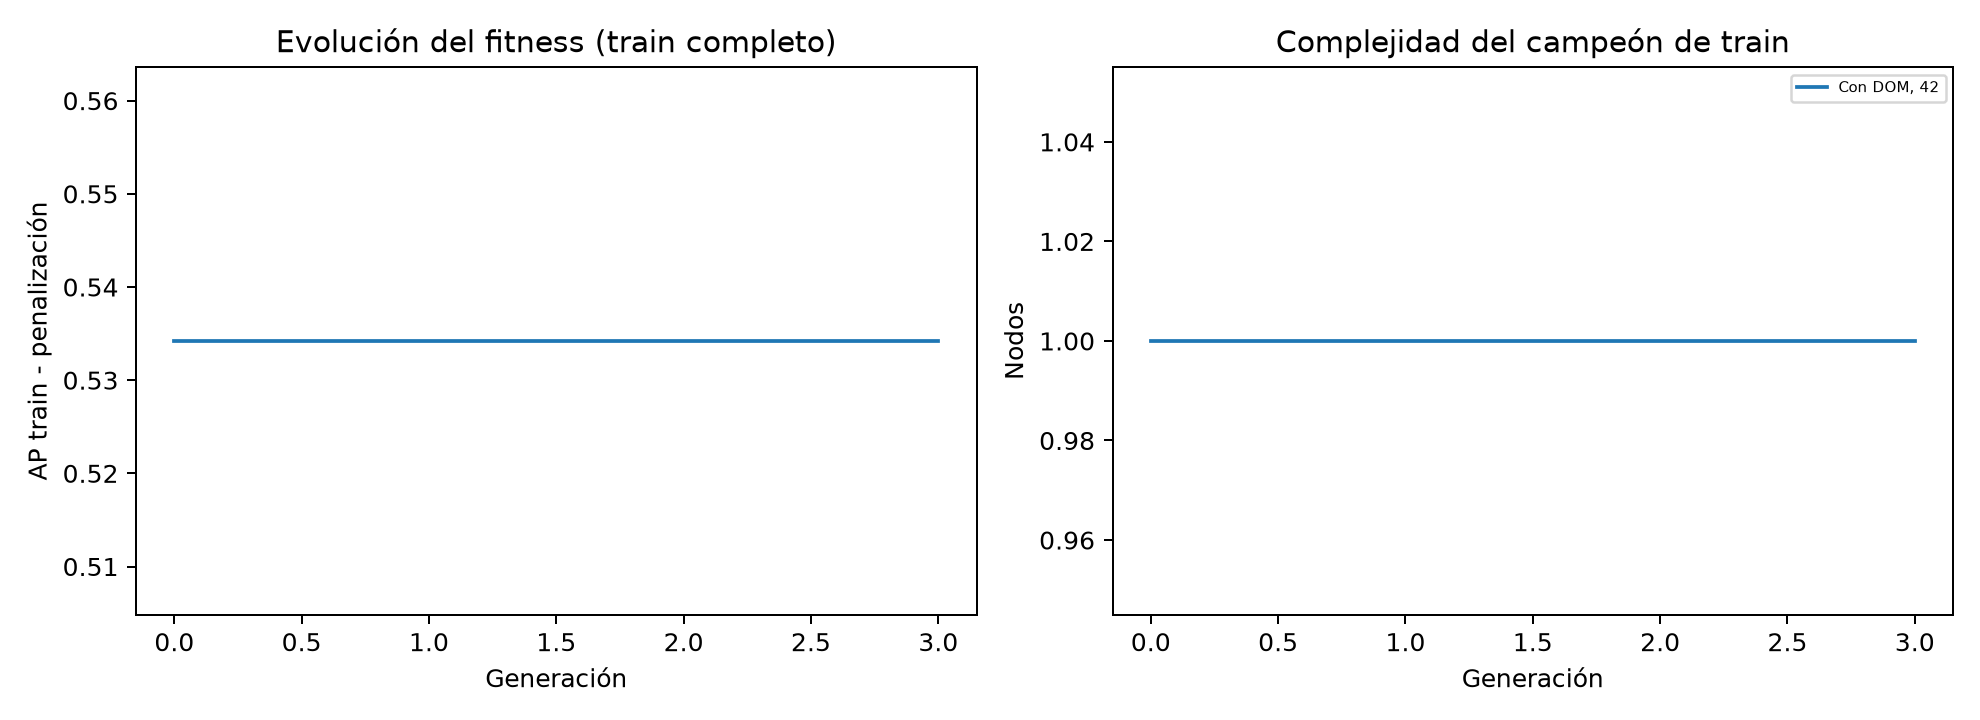

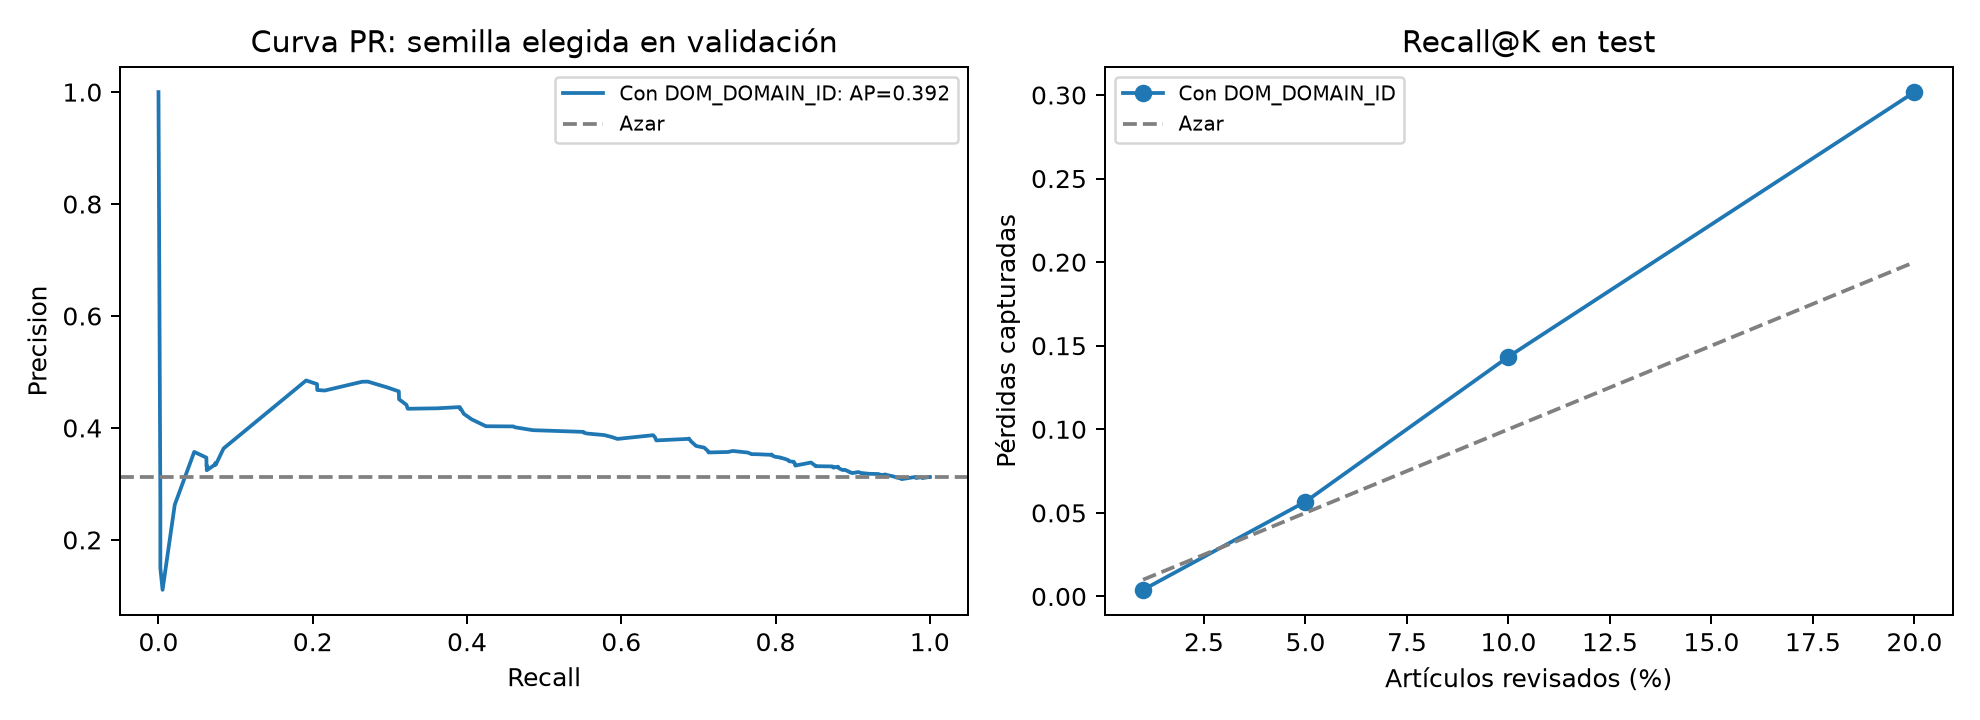

Resultados agregados: C:\Users\lizet\OneDrive\Documents\ChatGPT\proyecto SI\_review_riskship\riskship-rna-main\results\notebook_smoke
Los modelos con mapas de categorías son privados; no incluirlos en archivos públicos.


In [7]:
from IPython.display import Image, display
FIGURES = (OUTPUT / 'full' if MODE == 'full' else OUTPUT) / 'figures'
display(Image(filename=str(FIGURES / 'evolution.png')))
display(Image(filename=str(FIGURES / 'pr_and_ranking.png')))
print('Resultados agregados:', OUTPUT)
print('Los modelos con mapas de categorías son privados; no incluirlos en archivos públicos.')


## Resultados ampliados guardados

Si el paquete incluye la suite ya ejecutada, se muestra aquí su comparación
agregada de cinco semillas. Estos son resultados anteriores guardados; la prueba
smoke de las celdas anteriores tiene un presupuesto distinto y no los sustituye.


model,GP con dominio,GP sin dominio,RNA
metric,,,
f1,0.6039,0.5720,0.6259
pr_auc,0.6393,0.5767,0.7496
recall_at_20%,0.4450,0.3994,0.5060
roc_auc,0.7734,0.7517,0.8241


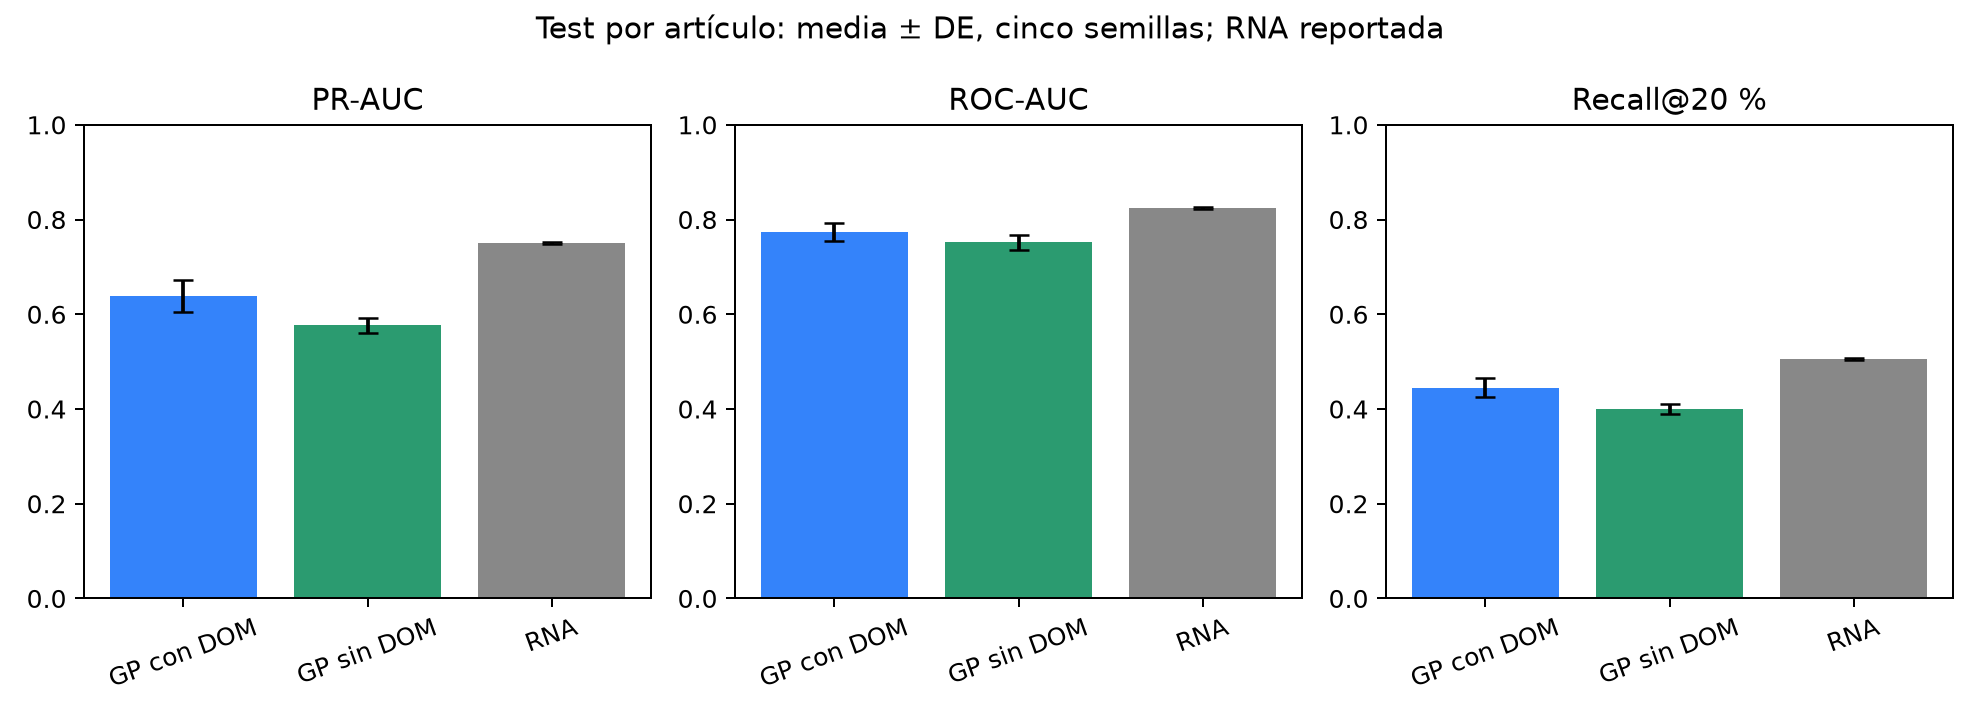

In [8]:
FULL_RESULTS = DATA_PATH.resolve().parent / 'results' / 'gp_full_v1'
comparison = FULL_RESULTS / 'comparison_rna_gp.csv'
if comparison.exists():
    measured = pd.read_csv(comparison)
    display(measured[measured['metric'].isin(['pr_auc', 'roc_auc', 'f1', 'recall_at_20%'])]
            .pivot(index='metric', columns='model', values='mean').round(4))
    display(Image(filename=str(FULL_RESULTS / 'figures' / 'rna_gp_comparison.png')))
else:
    print('Suite ampliada no disponible en este entorno. Ejecutar MODE=full para generarla.')


## Alcance de los resultados

Una corrida smoke valida funcionamiento. Para comparar, usar media y desviación
estándar de cinco semillas y la misma partición, con y sin `DOM_DOMAIN_ID`.
Las métricas son por artículo y sobre una muestra case-control; no describen
directamente precisión o probabilidad de producción. RNA usa umbral 0,5 y GP
selecciona F1 en validación, por lo que sus métricas de clasificación no tienen
el mismo punto operativo. PR-AUC y ranking permiten comparar sin ese umbral.

La RNA reportada tiene PR-AUC 0,7496 ± 0,0020 y ROC-AUC 0,8241 ± 0,0020.
Estas cifras proceden del repositorio; este notebook no reentrena la RNA.
